# Задание 4. Предсказание года выпуска песни

Задача из InClass-соревнования на Kaggle: по 90 числовым признакам аудио предсказать год выпуска песни. Данные - подвыборка YearPredictionMSD из Million Song Dataset: в основном западные коммерческие треки 1922-2011 годов, больше всего песен из 2000-х. Признаки посчитаны сервисом The Echo Nest по тембру, самого аудио в данных нет. Файлы `train_x.csv`, `train_y.csv`, `test_x.csv` (и `sample_submission.csv`, если он есть) со страницы соревнования нужно положить в папку `data/songs-prediction-2026/` рядом с ноутбуком (папка `data/` не коммитится). Метрика соревнования - MSE, причем предсказывать нужно целые годы. Ограничения: никакого ансамблирования (итоговое предсказание дает одна обученная модель), сама модель только на torch, numpy / sklearn / pandas - только для предобработки и сборки сабмишена, сторонние данные (в том числе полный YearPredictionMSD) использовать нельзя.

План: EDA -> схема валидации -> линейные бейзлайны -> MLP и эксперименты -> свой оптимизатор из задания 3 -> финальная модель и сабмишен -> описание решения.

In [1]:
import math
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import KFold
from sklearn.preprocessing import QuantileTransformer, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
torch.set_num_threads(2)  # машина общая, больше 2 потоков на маленьких сетях все равно не помогает

DATA = Path("data/songs-prediction-2026")
YMIN, YMAX = 1922, 2011

## 1. Данные и EDA

In [2]:
X_df = pd.read_csv(DATA / "train_x.csv", index_col=0)
y_ser = pd.read_csv(DATA / "train_y.csv", index_col=0)["year"]
test_df = pd.read_csv(DATA / "test_x.csv")
test_ids = test_df.pop("id")

FEATS = [str(i) for i in range(90)]
assert (X_df.index == y_ser.index).all() and list(X_df.columns) == FEATS and list(test_df.columns) == FEATS
X = X_df[FEATS].values.astype(np.float64)
y = y_ser.values.astype(np.float64)
X_test = test_df[FEATS].values.astype(np.float64)

print("train:", X.shape, "| test:", X_test.shape)
print("пропуски: train", int(X_df.isna().sum().sum()), "| target", int(y_ser.isna().sum()), "| test", int(test_df.isna().sum().sum()))
print("дубликаты строк в train:", int(X_df.duplicated().sum()), "| уникальных id в test:", test_ids.nunique())

train: (14000, 90) | test: (6000, 90)
пропуски: train 0 | target 0 | test 0
дубликаты строк в train: 0 | уникальных id в test: 6000


Первая (безымянная) колонка в `train_x.csv` / `train_y.csv` - это номер строки в исходном большом датасете, а не признак. Проверим, что с годом она не связана, и дальше ее не используем.

In [3]:
print(f"индекс: от {X_df.index.min()} до {X_df.index.max()}, corr(индекс, год) = {np.corrcoef(X_df.index, y)[0, 1]:.4f}")

индекс: от 25 до 515338, corr(индекс, год) = 0.0012


### Целевая переменная

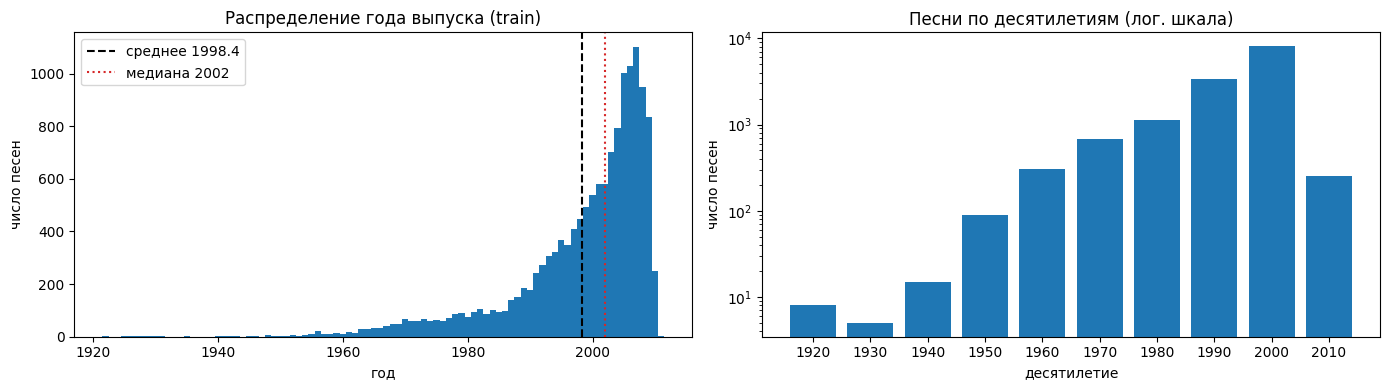

среднее 1998.37, std 11.05, медиана 2002, асимметрия -1.77
доля песен с 2000 года: 59.8%, до 1980 года: 8.0%


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(y, bins=np.arange(YMIN, YMAX + 2) - 0.5, color="C0")
axes[0].axvline(y.mean(), color="k", ls="--", label=f"среднее {y.mean():.1f}")
axes[0].axvline(np.median(y), color="C3", ls=":", label=f"медиана {np.median(y):.0f}")
axes[0].set(title="Распределение года выпуска (train)", xlabel="год", ylabel="число песен")
axes[0].legend()
dec = pd.Series((y // 10 * 10).astype(int)).value_counts().sort_index()
axes[1].bar(dec.index.astype(str), dec.values, color="C0")
axes[1].set_yscale("log")
axes[1].set(title="Песни по десятилетиям (лог. шкала)", xlabel="десятилетие", ylabel="число песен")
plt.tight_layout()
plt.show()

print(f"среднее {y.mean():.2f}, std {y.std():.2f}, медиана {np.median(y):.0f}, асимметрия {y_ser.skew():.2f}")
print(f"доля песен с 2000 года: {(y >= 2000).mean():.1%}, до 1980 года: {(y < 1980).mean():.1%}")

Распределение сильно скошено влево: 60% песен вышли в 2000 году и позже, а до 1980 года - только 8%, это длинный хвост. Константа (среднее) дает MSE, равную дисперсии таргета, примерно 122 (RMSE около 11) - от этого и будем отталкиваться. Ошибки на старых песнях будут большими, и в MSE они весят сильно, поэтому предсказывать матожидание (MSE-лосс) правильнее, чем, например, медиану.

### Признаки

По описанию датасета признаки 0-11 - средние значения 12 тембровых коэффициентов по сегментам песни, 12-89 - элементы ковариационной матрицы этих коэффициентов (12·13/2 = 78 штук). Признаки 12-23 во всех строках положительные, т.е. это дисперсии, а 24-89 - 66 ковариаций. Посмотрим на масштабы и хвосты.

признаки 12-23 > 0 во всех строках: True | другие всегда > 0: [0]


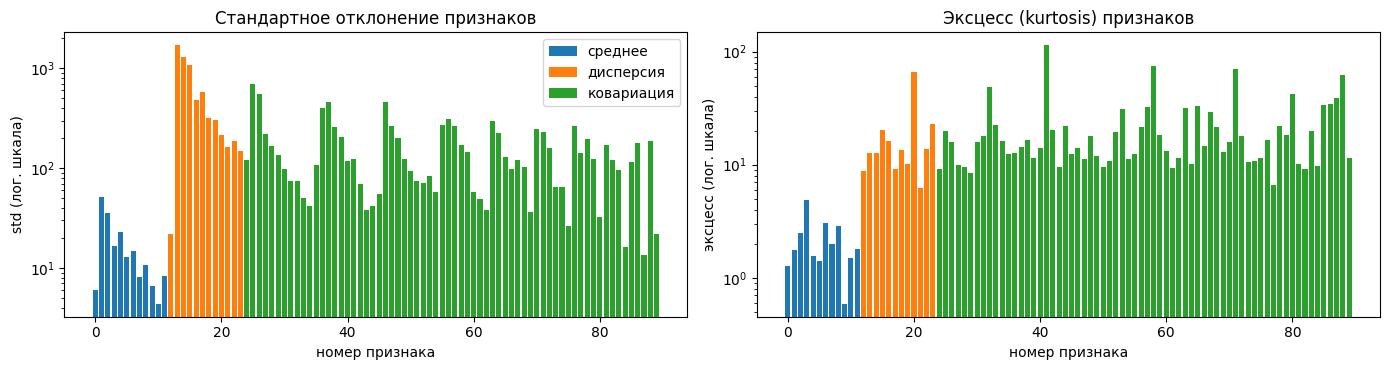

              std  kurtosis
group                      
среднее      11.8       1.8
дисперсия   309.8      13.1
ковариация  120.1      15.8


In [5]:
group = np.array(["среднее"] * 12 + ["дисперсия"] * 12 + ["ковариация"] * 66)
print("признаки 12-23 > 0 во всех строках:", bool((X[:, 12:24] > 0).all()), "| другие всегда > 0:",
      [f for f in range(90) if f not in range(12, 24) and (X[:, f] > 0).all()])

feat_stats = pd.DataFrame({"group": group, "std": X_df.std().values, "kurtosis": X_df.kurt().values,
                           "corr": X_df.corrwith(y_ser).values}, index=FEATS)
colors = {"среднее": "C0", "дисперсия": "C1", "ковариация": "C2"}

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for g_name, c in colors.items():
    idx = np.where(group == g_name)[0]
    axes[0].bar(idx, feat_stats["std"].values[idx], color=c, label=g_name)
    axes[1].bar(idx, feat_stats["kurtosis"].values[idx], color=c, label=g_name)
axes[0].set(yscale="log", title="Стандартное отклонение признаков", xlabel="номер признака", ylabel="std (лог. шкала)")
axes[1].set(yscale="log", title="Эксцесс (kurtosis) признаков", xlabel="номер признака", ylabel="эксцесс (лог. шкала)")
axes[0].legend()
plt.tight_layout()
plt.show()
print(feat_stats.groupby("group", sort=False)[["std", "kurtosis"]].median().round(1))

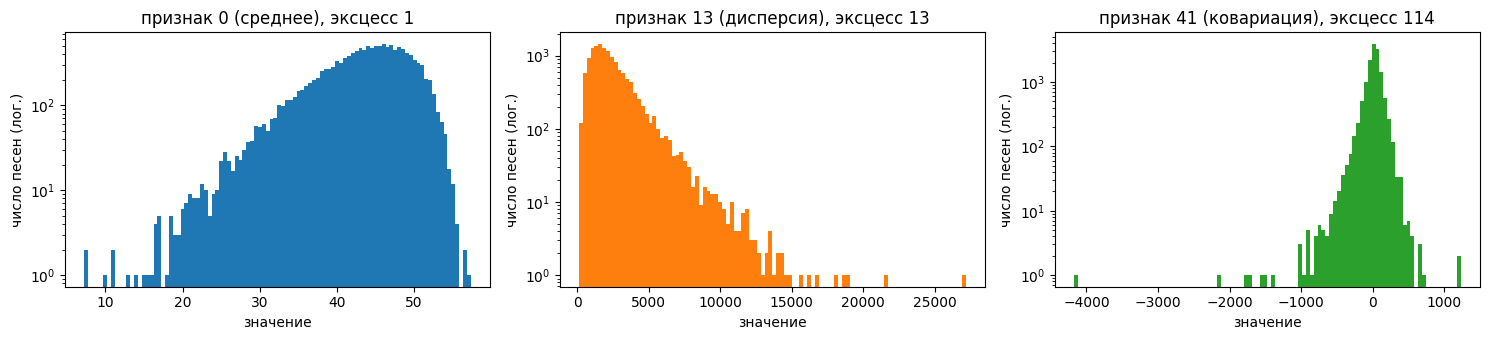

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, f in zip(axes, ["0", "13", "41"]):
    ax.hist(X_df[f], bins=100, color=colors[feat_stats.loc[f, "group"]])
    ax.set_yscale("log")
    ax.set(title=f"признак {f} ({feat_stats.loc[f, 'group']}), эксцесс {feat_stats.loc[f, 'kurtosis']:.0f}",
           xlabel="значение", ylabel="число песен (лог.)")
plt.tight_layout()
plt.show()

Масштабы признаков отличаются почти на 3 порядка (std от 4 у средних до 1700 у дисперсий). У средних тембра хвосты умеренные (эксцесс около 2), а у дисперсий и ковариаций медианный эксцесс 13-16, у нескольких признаков больше 60, а у признака 41 - больше 100. Значит, признаки обязательно нужно масштабировать, и стоит попробовать что-то устойчивое к выбросам (QuantileTransformer) помимо обычного StandardScaler.

Теперь - насколько каждый признак связан с годом.

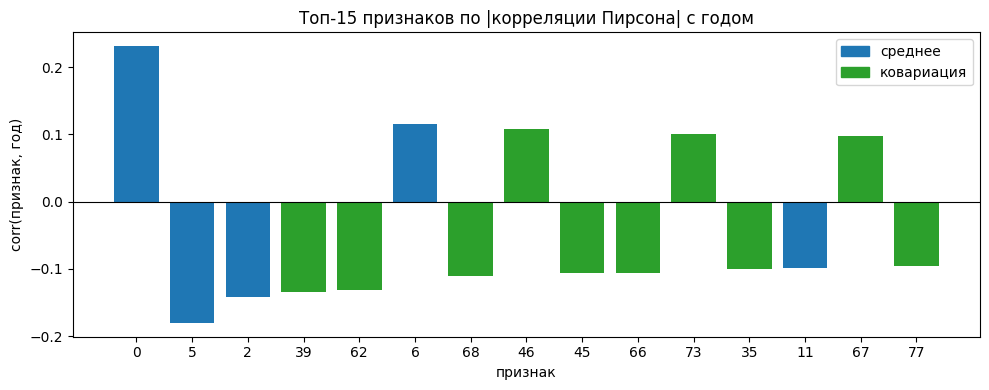

максимальная |corr|: 0.231 | признаков с |corr| > 0.1: 12


In [7]:
top = feat_stats.reindex(feat_stats["corr"].abs().sort_values(ascending=False).index).head(15)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(top.index, top["corr"], color=[colors[g_name] for g_name in top["group"]])
ax.axhline(0, color="k", lw=0.8)
ax.set(title="Топ-15 признаков по |корреляции Пирсона| с годом", xlabel="признак", ylabel="corr(признак, год)")
present = [g_name for g_name in colors if g_name in set(top["group"])]
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=colors[g_name]) for g_name in present], labels=present)
plt.tight_layout()
plt.show()
print("максимальная |corr|:", top["corr"].abs().max().round(3), "| признаков с |corr| > 0.1:", int((feat_stats["corr"].abs() > 0.1).sum()))

По отдельности признаки связаны с годом слабо: самый сильный - признак 0 (среднее первого тембрового коэффициента, он связан с громкостью), у него |corr| = 0.23, а |corr| > 0.1 только у 12 признаков. В топе и средние тембра, и ковариации, так что выбрасывать ковариации не стоит. Сигнал размазан по многим слабым признакам, поэтому от линейной модели многого не ждем, а нелинейная модель может собрать из них больше.

Напоследок проверим, что тест похож на трейн (иначе валидация на трейне мало что скажет про лидерборд).

In [8]:
smd = (X_test.mean(0) - X.mean(0)) / X.std(0)
print(f"max |разность средних train/test| в единицах std: {np.abs(smd).max():.3f}")

max |разность средних train/test| в единицах std: 0.035


Сдвига нет, так что будем доверять кросс-валидации на трейне.

## 2. Схема валидации

- 5-fold `KFold(shuffle=True, random_state=42)` по 14000 строкам трейна, фолды одни и те же для всех экспериментов;
- вся предобработка (скейлеры, трансформации, нормировка таргета) обучается только на трейн-части фолда, поэтому она спрятана внутрь функции обучения;
- основная метрика - MSE. Считаю две версии: `MSE` на сырых (вещественных) предсказаниях и `MSE(int)` после официальной постобработки (обрезка в [1922, 2011] и округление до целого) - именно она соответствует лидерборду. Дополнительно RMSE и MAE. Везде среднее и std по 5 фолдам;
- сиды torch фиксированы: на фолде k модель инициализируется и перемешивает батчи с сидом k (в одной проверке ниже - с сидом k + 100);
- у нейросетей фиксированное число эпох и расписание lr (число эпох тоже выбирается по CV, п. 4.3), никакого early stopping. Валидационная часть фолда в обучении не участвует, по ней только рисуются кривые обучения для иллюстрации.

In [9]:
N_FOLDS = 5
FOLDS = list(KFold(n_splits=N_FOLDS, shuffle=True, random_state=42).split(X))
RESULTS = {}  # имя варианта -> метрики по фолдам


def postprocess(pred):
    """Официальная постобработка: годы в [1922, 2011], целые."""
    return np.clip(np.rint(pred), YMIN, YMAX).astype(int)


def fold_metrics(y_true, pred):
    pred_int = postprocess(pred)
    return {
        "mse": np.mean((pred - y_true) ** 2),
        "mse_clip": np.mean((np.clip(pred, YMIN, YMAX) - y_true) ** 2),
        "mse_int": np.mean((pred_int - y_true) ** 2),
        "rmse": np.sqrt(np.mean((pred - y_true) ** 2)),
        "mae": np.mean(np.abs(pred - y_true)),
    }


def cross_validate(fit_predict, name, seed_offset=0, verbose=True, **cfg):
    """5-fold CV. fit_predict(X_tr, y_tr, X_va, seed=..., **cfg) -> предсказания (годы, float).
    На фолде k сид = k + seed_offset.
    Вся предобработка делается внутри fit_predict, т.е. учится только на трейн-части фолда.
    y_va передается только для логирования кривых обучения, на обучение он не влияет."""
    rows, oof, curves = [], np.zeros(len(y)), []
    t0 = time.time()
    for k, (tr, va) in enumerate(FOLDS):
        out = fit_predict(X[tr], y[tr], X[va], seed=k + seed_offset, y_va=y[va], **cfg)
        pred, curve = out if isinstance(out, tuple) else (out, None)
        oof[va] = pred
        rows.append(fold_metrics(y[va], pred))
        curves.append(curve)
    folds = pd.DataFrame(rows)
    res = {"folds": folds, "oof": oof, "curves": curves, "sec_per_fold": (time.time() - t0) / N_FOLDS}
    RESULTS[name] = res
    if verbose:
        m, s = folds.mean(), folds.std(ddof=0)
        print(f"{name:<38} MSE {m.mse:7.3f} ± {s.mse:.3f} | MSE(int) {m.mse_int:7.3f} | "
              f"RMSE {m.rmse:.4f} | MAE {m.mae:.4f} | {res['sec_per_fold']:.1f} с/фолд")
    return res


def summary_table(names=None):
    names = names or list(RESULTS)
    rows = []
    for n in names:
        f = RESULTS[n]["folds"]
        rows.append({"вариант": n, "MSE": f.mse.mean(), "MSE std": f.mse.std(ddof=0), "MSE(int)": f.mse_int.mean(),
                     "MSE(int) std": f.mse_int.std(ddof=0), "RMSE": f.rmse.mean(), "MAE": f.mae.mean(),
                     "вклад обрезки": f.mse_clip.mean() - f.mse.mean(), "вклад округления": f.mse_int.mean() - f.mse_clip.mean()})
    return pd.DataFrame(rows).set_index("вариант")

## 3. Бейзлайны

Константа и линейная регрессия. Линейную модель считаю в замкнутой форме прямо на torch: $w = (A^\top A + \alpha I)^{-1} A^\top (y - \bar y)$ на центрированных стандартизованных признаках ($\alpha = 0$ - обычный МНК, $\alpha > 0$ - ridge).

In [10]:
def make_prep(kind):
    if kind == "std":
        return StandardScaler()
    if kind == "quantile":
        return QuantileTransformer(n_quantiles=1000, output_distribution="normal", subsample=10**9, random_state=0)
    raise ValueError(kind)


def fit_const(X_tr, y_tr, X_va, seed=0, y_va=None):
    return np.full(len(X_va), y_tr.mean())


def fit_ridge(X_tr, y_tr, X_va, seed=0, y_va=None, alpha=0.0, prep="std"):
    """Линейная регрессия / ridge в замкнутой форме на torch (свободный член не штрафуется)."""
    pre = make_prep(prep).fit(X_tr)
    A = torch.tensor(pre.transform(X_tr), dtype=torch.float64)
    B = torch.tensor(pre.transform(X_va), dtype=torch.float64)
    yt = torch.tensor(y_tr, dtype=torch.float64)
    mu_x, mu_y = A.mean(0), yt.mean()
    A = A - mu_x
    w = torch.linalg.solve(A.T @ A + alpha * torch.eye(A.shape[1], dtype=A.dtype), A.T @ (yt - mu_y))
    return ((B - mu_x) @ w + mu_y).numpy()


cross_validate(fit_const, "константа (среднее)")
cross_validate(fit_ridge, "линейная регрессия (МНК)")
cross_validate(fit_ridge, "ridge, alpha=10", alpha=10.0)
cross_validate(fit_ridge, "ridge, alpha=1000", alpha=1000.0)
cross_validate(fit_ridge, "ridge, alpha=10, QuantileTransformer", alpha=10.0, prep="quantile");

константа (среднее)                    MSE 122.069 ± 3.415 | MSE(int) 122.186 | RMSE 11.0474 | MAE 8.2199 | 0.0 с/фолд


линейная регрессия (МНК)               MSE  93.511 ± 2.305 | MSE(int)  93.001 | RMSE 9.6694 | MAE 6.8543 | 0.1 с/фолд


ridge, alpha=10                        MSE  93.504 ± 2.310 | MSE(int)  92.996 | RMSE 9.6690 | MAE 6.8545 | 0.1 с/фолд


ridge, alpha=1000                      MSE  94.068 ± 2.584 | MSE(int)  93.798 | RMSE 9.6980 | MAE 6.9221 | 0.1 с/фолд


ridge, alpha=10, QuantileTransformer   MSE  91.464 ± 1.970 | MSE(int)  91.389 | RMSE 9.5631 | MAE 6.7563 | 0.5 с/фолд


Линейная регрессия снижает MSE со 122 до 93.5 (RMSE 9.67), и на этом все. Ridge с alpha=10 дает то же самое, alpha=1000 уже хуже: признаков всего 90 на 11 тысяч строк, переобучаться линейной модели почти не на чем. QuantileTransformer (каждый признак по рангам переводится в нормальное распределение) улучшает ridge до 91.5 - видимо, из-за тяжелых хвостов: выбросы перестают тянуть веса на себя. Это лучший линейный результат.

У линейных моделей MSE(int) даже меньше сырой MSE. Это эффект не округления, а обрезки: часть предсказаний вылезает за 2011 год.

Сразу посмотрим, сколько стоит обязательное округление до целого. Если $r = \mathrm{round}(p) - p$ - ошибка округления, то $\mathrm{MSE(int)} - \mathrm{MSE} = \mathbb E[r^2] + 2\,\mathbb E[r\,(p - y)]$. Ошибка округления почти равномерна на $[-0.5, 0.5]$ и не связана с остатком $p - y$, поэтому ожидаем прибавку около $\mathbb E[r^2] = 1/12 \approx 0.083$. При квадратичной ошибке округление к ближайшему целому - лучшее, что можно сделать с целыми ответами, так что эту плату просто принимаем.

In [11]:
def mse(pred):
    return np.mean((pred - y) ** 2)


oof = RESULTS["ridge, alpha=10"]["oof"]
clipped = np.clip(oof, YMIN, YMAX)
r = postprocess(oof) - clipped  # ошибка только от округления
print(f"предсказаний ridge вне [1922, 2011]: {np.mean((oof < YMIN) | (oof > YMAX)):.2%}, максимум {oof.max():.1f}")
print(f"MSE: сырые {mse(oof):.3f} -> после обрезки {mse(clipped):.3f} -> после обрезки и округления {mse(postprocess(oof)):.3f}")
print(f"вклад округления = {mse(postprocess(oof)) - mse(clipped):.4f}:  E[r^2] = {np.mean(r ** 2):.4f} (1/12 = {1 / 12:.4f}), "
      f"2 E[r (pred - y)] = {2 * np.mean(r * (clipped - y)):.4f}")

предсказаний ridge вне [1922, 2011]: 0.84%, максимум 2039.7
MSE: сырые 93.504 -> после обрезки 92.861 -> после обрезки и округления 92.996
вклад округления = 0.1350:  E[r^2] = 0.0816 (1/12 = 0.0833), 2 E[r (pred - y)] = 0.0534


Если разделить постобработку на два шага, все сходится. Обрезка у ridge уменьшает MSE на 0.64: 0.84% предсказаний вылезают за 2011 год (максимум - 2039.7). Округление добавляет 0.135, из них $\mathbb E[r^2] = 0.082$ - практически ровно $1/12$, а остальное - перекрестный член. В среднем он нулевой, но на 14000 точках шумит: его std порядка $2\sqrt{\mathbb E[r^2]\cdot \mathrm{MSE}/n} \approx 0.05$. В итоговой таблице ниже вклад обрезки и вклад округления посчитаны отдельно для каждого варианта.

## 4. Нейросеть

Модель - обычный MLP: `Linear -> BatchNorm1d -> ReLU -> Dropout` x 2 слоя по 256 и `Linear(256, 1)` на выходе. Признаки стандартизуются (StandardScaler), таргет тоже: $(y - \bar y) / \sigma_y$ по трейн-части, лосс MSE, на выходе обратное преобразование. Оптимизатор AdamW (lr $10^{-3}$, weight decay $10^{-2}$), батч 512, 20 эпох с расписанием OneCycle (lr растет первые 30% шагов, потом косинусом падает почти до нуля, шаг шедулера на каждом батче).

Одна функция `fit_mlp` покрывает все варианты ниже (препроцессинг, архитектура, лосс, шум на входе, оптимизатор), конфигурация задается словарем, `BASE` - отправная точка.

In [12]:
ACTS = {"relu": nn.ReLU, "silu": nn.SiLU}
NORMS = {"bn": nn.BatchNorm1d, "ln": nn.LayerNorm}
YEARS = torch.arange(YMIN, YMAX + 1, dtype=torch.float32)  # 90 классов для CE-постановки


class MLP(nn.Module):
    def __init__(self, d_in, hidden=(256, 256), d_out=1, norm="bn", act="relu", dropout=0.0):
        super().__init__()
        layers, d = [], d_in
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if norm:
                layers.append(NORMS[norm](h))
            layers.append(ACTS[act]())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            d = h
        layers.append(nn.Linear(d, d_out))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


BASE = dict(prep="std", hidden=(256, 256), norm="bn", act="relu", dropout=0.0, loss="mse", noise=0.0,
            lr=1e-3, wd=1e-2, bs=512, epochs=20, sched="onecycle", opt="adamw")


def make_scheduler(opt, kind, total):
    if kind == "onecycle":
        return torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=opt.defaults["lr"], total_steps=total, pct_start=0.3)
    # линейный warmup на 5% шагов, потом косинус до нуля
    warm = max(1, int(0.05 * total))
    return torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / (total - warm))))


def fit_mlp(X_tr, y_tr, X_va, seed=0, y_va=None, return_model=False, **cfg):
    cfg = {**BASE, **cfg}
    pre = make_prep(cfg["prep"]).fit(X_tr)
    Xt = torch.tensor(pre.transform(X_tr), dtype=torch.float32)
    Xv = torch.tensor(pre.transform(X_va), dtype=torch.float32)
    mu, sd = y_tr.mean(), y_tr.std()
    if cfg["loss"] == "ce":
        target = torch.tensor(np.clip(y_tr, YMIN, YMAX) - YMIN, dtype=torch.long)
    else:
        target = torch.tensor((y_tr - mu) / sd, dtype=torch.float32)

    torch.manual_seed(seed)
    g = torch.Generator().manual_seed(seed)
    model = MLP(Xt.shape[1], cfg["hidden"], len(YEARS) if cfg["loss"] == "ce" else 1,
                cfg["norm"], cfg["act"], cfg["dropout"])
    opt_cls = MyAdamW if cfg["opt"] == "my" else torch.optim.AdamW
    opt = opt_cls(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    n, bs = len(Xt), cfg["bs"]
    sched = make_scheduler(opt, cfg["sched"], cfg["epochs"] * math.ceil(n / bs))

    def loss_fn(out, t):
        if cfg["loss"] == "ce":
            return F.cross_entropy(out, t)
        if cfg["loss"] == "huber":
            return F.huber_loss(out[:, 0], t, delta=1.0)
        return F.mse_loss(out[:, 0], t)

    @torch.no_grad()
    def predict(Xe):
        model.eval()
        out = model(Xe)
        model.train()
        if cfg["loss"] == "ce":
            return (out.softmax(1) * YEARS).sum(1).double().numpy()  # матожидание года
        return out[:, 0].double().numpy() * sd + mu

    curve = {"train_loss": [], "val_mse": []}
    model.train()
    for ep in range(cfg["epochs"]):
        perm, tot = torch.randperm(n, generator=g), 0.0
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            if len(idx) < 2:  # BatchNorm не работает на батче из одного объекта
                continue
            xb = Xt[idx]
            if cfg["noise"] > 0:
                xb = xb + cfg["noise"] * torch.randn(xb.shape, generator=g)
            loss = loss_fn(model(xb), target[idx])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
            tot += loss.item() * len(idx)
        curve["train_loss"].append(tot / n)
        if y_va is not None:
            curve["val_mse"].append(np.mean((predict(Xv) - y_va) ** 2))
    pred = predict(Xv)
    if return_model:
        return pred, curve, model
    return pred, curve


def plot_curves(names, title, labels=None):
    """Средняя по фолдам MSE на валидации после каждой эпохи (только для иллюстрации)."""
    fig, ax = plt.subplots(figsize=(9, 4))
    for n, lab in zip(names, labels or names):
        c = np.mean([cv["val_mse"] for cv in RESULTS[n]["curves"]], axis=0)
        ax.plot(np.arange(1, len(c) + 1), c, marker=".", label=lab)
        print(f"{n}: минимум {c.min():.2f} на эпохе {c.argmin() + 1}, после последней эпохи {c[-1]:.2f}")
    ax.set(title=title, xlabel="эпоха", ylabel="MSE на валидации (среднее по фолдам)")
    ax.set_ylim(top=min(ax.get_ylim()[1], 110))
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

### 4.1. Первая MLP и регуляризация

Сначала сеть без dropout, потом добавляем dropout 0.2 и 0.4.

MLP 256x2, без dropout                 MSE  95.770 ± 2.587 | MSE(int)  94.152 | RMSE 9.7853 | MAE 7.0357 | 5.6 с/фолд


MLP 256x2, dropout 0.2                 MSE  83.955 ± 1.703 | MSE(int)  83.911 | RMSE 9.1622 | MAE 6.4220 | 6.9 с/фолд


MLP 256x2, dropout 0.4                 MSE  83.312 ± 1.544 | MSE(int)  83.396 | RMSE 9.1271 | MAE 6.4112 | 7.0 с/фолд
MLP 256x2, без dropout: минимум 90.89 на эпохе 5, после последней эпохи 95.77
MLP 256x2, dropout 0.2: минимум 83.95 на эпохе 20, после последней эпохи 83.95
MLP 256x2, dropout 0.4: минимум 83.28 на эпохе 19, после последней эпохи 83.31


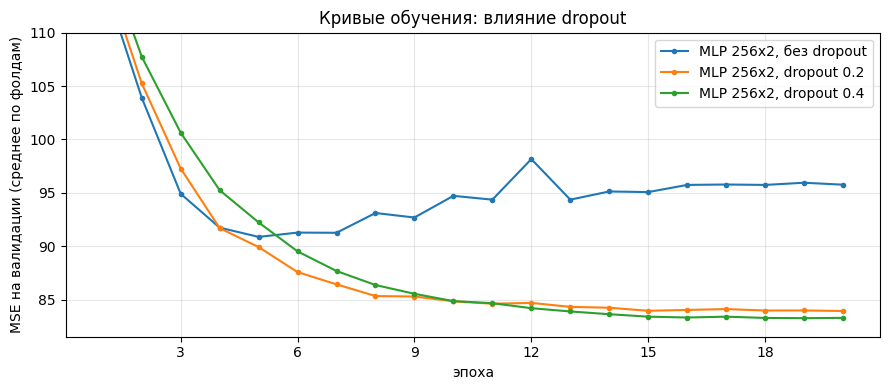

In [13]:
cross_validate(fit_mlp, "MLP 256x2, без dropout")
for p in [0.2, 0.4]:
    cross_validate(fit_mlp, f"MLP 256x2, dropout {p}", dropout=p)
plot_curves(["MLP 256x2, без dropout", "MLP 256x2, dropout 0.2", "MLP 256x2, dropout 0.4"],
            "Кривые обучения: влияние dropout")

Без dropout сеть переобучается очень быстро: средняя валидационная MSE минимальна уже на 5-й эпохе (90.9), а к концу обучения вырастает до 95.8 - хуже линейной модели. Dropout это лечит: 84.0 с p=0.2 и 83.3 с p=0.4, и кривые падают почти до самого конца расписания (минимум на 19-20-й эпохе), т.е. за 20 эпох сеть с dropout не переобучается (подходит ли сама длина расписания, проверю отдельно в п. 4.3). Оставляю dropout 0.4.

### 4.2. Learning rate

С dropout 0.4 сеть за 20 эпох уже не переобучается, и теперь, наоборот, можно учить агрессивнее: попробуем больший lr (это максимальный lr в OneCycle).

In [14]:
for lr in [2e-3, 4e-3]:
    cross_validate(fit_mlp, f"MLP, dropout 0.4, lr {lr:g}", dropout=0.4, lr=lr)
BEST = dict(dropout=0.4, lr=2e-3)
BEST_NAME = "MLP, dropout 0.4, lr 0.002"

MLP, dropout 0.4, lr 0.002             MSE  81.977 ± 1.368 | MSE(int)  82.088 | RMSE 9.0538 | MAE 6.3261 | 7.2 с/фолд


MLP, dropout 0.4, lr 0.004             MSE  82.386 ± 1.306 | MSE(int)  82.463 | RMSE 9.0764 | MAE 6.2951 | 9.0 с/фолд


lr 2e-3 дает заметный выигрыш: 82.0 против 83.3 при 1e-3, а 4e-3 уже чуть хуже (82.4). Видимо, при 1e-3 сеть с сильным dropout за 20 эпох не доучивалась. Эту конфигурацию (`BEST`: 256x2, BatchNorm, ReLU, dropout 0.4, lr 2e-3) дальше пытаюсь улучшить.

### 4.3. Число эпох и расписание

20 эпох я взял с самого начала, не подбирая. Проверим это на CV: тот же `BEST` с 10, 30 и 40 эпохами (OneCycle каждый раз растягивается на все шаги), а также 20 эпох с другим расписанием - линейный warmup на 5% шагов, потом косинус до нуля.

BEST, 10 эпох                          MSE  83.642 ± 1.531 | MSE(int)  83.682 | RMSE 9.1452 | MAE 6.4329 | 4.6 с/фолд


BEST, 30 эпох                          MSE  82.252 ± 1.421 | MSE(int)  82.397 | RMSE 9.0690 | MAE 6.2914 | 10.6 с/фолд


BEST, 40 эпох                          MSE  83.535 ± 1.600 | MSE(int)  83.658 | RMSE 9.1393 | MAE 6.2968 | 14.6 с/фолд


BEST, warmup + косинус вместо OneCycle MSE  82.220 ± 1.261 | MSE(int)  82.207 | RMSE 9.0673 | MAE 6.3333 | 6.8 с/фолд


BEST, 10 эпох: минимум 83.64 на эпохе 10, после последней эпохи 83.64
MLP, dropout 0.4, lr 0.002: минимум 81.95 на эпохе 15, после последней эпохи 81.98
BEST, 30 эпох: минимум 82.07 на эпохе 20, после последней эпохи 82.25
BEST, 40 эпох: минимум 82.49 на эпохе 18, после последней эпохи 83.54


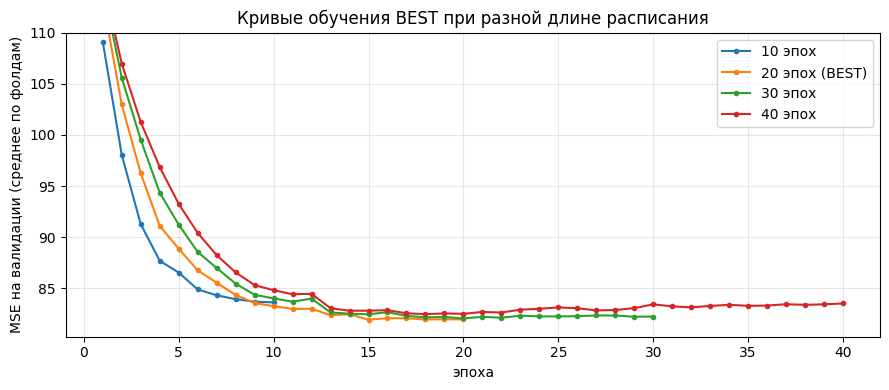

In [15]:
for ep in [10, 30, 40]:
    cross_validate(fit_mlp, f"BEST, {ep} эпох", **BEST, epochs=ep)
cross_validate(fit_mlp, "BEST, warmup + косинус вместо OneCycle", **BEST, sched="cosine")
plot_curves(["BEST, 10 эпох", BEST_NAME, "BEST, 30 эпох", "BEST, 40 эпох"], "Кривые обучения BEST при разной длине расписания",
            labels=["10 эпох", "20 эпох (BEST)", "30 эпох", "40 эпох"])

20 эпох оказались как раз оптимумом: с 10 эпохами сеть недоучивается (83.64), 30 эпох дают 82.25, а 40 - уже 83.54, хотя все отличие только в длине расписания. На кривых видно, что при 40 эпохах валидационная MSE доходит до минимума (около 82.5) примерно к 18-й эпохе, пока lr еще большой, а дальше, когда lr падает, сеть начинает переобучаться и к концу ухудшается до 83.5. То есть dropout 0.4 переобучение не убирает, а только откладывает, и длинное расписание вредит. Warmup + косинус дает 82.22 против 81.98 у OneCycle: разница 0.24, меньше, чем сдвиг самого `BEST` при смене сидов (0.29, см. п. 4.6), поэтому оставляю OneCycle. Итого фиксированное расписание выбрано по CV: 20 эпох с OneCycle.

### 4.4. Предобработка и архитектура

Дальше все варианты отличаются от `BEST` одним изменением: QuantileTransformer вместо StandardScaler, LayerNorm вместо BatchNorm, SiLU вместо ReLU, третий скрытый слой.

In [16]:
cross_validate(fit_mlp, "BEST + QuantileTransformer", **BEST, prep="quantile")
cross_validate(fit_mlp, "BEST + LayerNorm вместо BatchNorm", **BEST, norm="ln")
cross_validate(fit_mlp, "BEST + SiLU вместо ReLU", **BEST, act="silu")
cross_validate(fit_mlp, "BEST + 3 слоя по 256", **BEST, hidden=(256, 256, 256));

BEST + QuantileTransformer             MSE  82.301 ± 1.494 | MSE(int)  82.353 | RMSE 9.0716 | MAE 6.3353 | 7.1 с/фолд


BEST + LayerNorm вместо BatchNorm      MSE  83.499 ± 1.071 | MSE(int)  83.595 | RMSE 9.1376 | MAE 6.2156 | 6.5 с/фолд


BEST + SiLU вместо ReLU                MSE  82.722 ± 1.534 | MSE(int)  82.829 | RMSE 9.0948 | MAE 6.3314 | 6.6 с/фолд


BEST + 3 слоя по 256                   MSE  82.809 ± 1.348 | MSE(int)  82.796 | RMSE 9.0996 | MAE 6.3987 | 8.7 с/фолд


Ничего из этого не помогло:
- QuantileTransformer - 82.3. Для сети, в отличие от ridge, хватает StandardScaler: с хвостами справляются BatchNorm и нелинейность;
- LayerNorm заметно хуже BatchNorm - 83.5;
- SiLU вместо ReLU - 82.7, тоже хуже;
- третий слой - 82.8, и обучение заметно дольше. Двух слоев на 11 тысячах строк хватает.

### 4.5. Лосс и постановка задачи

Метрика - MSE, так что естественный лосс - тоже MSE. Но таргет скошен и с длинным хвостом старых песен, поэтому попробуем:
- Huber (на стандартизованном таргете, delta = 1, т.е. около 11 лет) - устойчив к выбросам;
- классификацию: 90 классов (по одному на год 1922-2011), кросс-энтропия, а предсказание - матожидание года по предсказанному распределению $\hat y = \sum_k p_k \cdot \text{year}_k$ (матожидание оптимально как раз для MSE).

In [17]:
cross_validate(fit_mlp, "BEST + Huber loss", **BEST, loss="huber")
cross_validate(fit_mlp, "BEST + CE по годам (матожидание)", **BEST, loss="ce");

BEST + Huber loss                      MSE  83.123 ± 1.915 | MSE(int)  83.206 | RMSE 9.1166 | MAE 6.1549 | 5.0 с/фолд


BEST + CE по годам (матожидание)       MSE  83.276 ± 1.028 | MSE(int)  83.310 | RMSE 9.1254 | MAE 6.5093 | 5.5 с/фолд


Обе альтернативы хуже по MSE: Huber 83.1, CE 83.3. Зато у Huber лучшая MAE из всех вариантов (6.15 против 6.33 у BEST). Так и должно быть: Huber тянет предсказания к условной медиане, а при скошенном таргете медиана и среднее заметно отличаются, для MSE же нужно именно среднее. CE на этой архитектуре и расписании проигрывает обычной регрессии примерно 1.3; возможно, ей нужны свои гиперпараметры, но выигрыша я не увидел и оставил MSE.

### 4.6. Шум на входе

Еще один популярный прием регуляризации для табличных данных - добавлять к стандартизованным признакам гауссов шум на каждом батче (аугментация, по смыслу близко к L2-регуляризации, Bishop 1995).

In [18]:
cross_validate(fit_mlp, "BEST + шум 0.1 на входе", **BEST, noise=0.1)
diff = RESULTS["BEST + шум 0.1 на входе"]["folds"].mse - RESULTS[BEST_NAME]["folds"].mse
print("разность MSE по фолдам (с шумом - без шума):", diff.round(3).tolist())

BEST + шум 0.1 на входе                MSE  81.896 ± 1.375 | MSE(int)  81.986 | RMSE 9.0493 | MAE 6.3378 | 5.1 с/фолд
разность MSE по фолдам (с шумом - без шума): [0.25, 0.14, -0.533, 0.006, -0.268]


С шумом получилось 81.90 против 81.98, т.е. разница 0.08 при std по фолдам около 1.4, и по фолдам она разного знака (от -0.53 до +0.25). Чтобы понять, улучшение это или случайность, перезапущу оба варианта с другими сидами (фолды те же).

In [19]:
cross_validate(fit_mlp, "BEST, сиды +100", seed_offset=100, **BEST)
cross_validate(fit_mlp, "BEST + шум 0.1, сиды +100", seed_offset=100, **BEST, noise=0.1);

BEST, сиды +100                        MSE  82.266 ± 1.058 | MSE(int)  82.327 | RMSE 9.0699 | MAE 6.3415 | 4.4 с/фолд


BEST + шум 0.1, сиды +100              MSE  82.235 ± 1.036 | MSE(int)  82.199 | RMSE 9.0682 | MAE 6.3467 | 4.2 с/фолд


С другими сидами: 82.24 с шумом против 82.27 без шума (MSE(int) 82.20 против 82.33). Шум опять чуть впереди, но всего на 0.03-0.08 по MSE, а сам `BEST` при смене сидов сдвигается на 0.29. Разница между вариантами намного меньше разброса от сидов, т.е. отличимого от шума эффекта нет, поэтому оставляю более простую модель - без шума на входе.

### Итоговая таблица экспериментов

,MSE,MSE std,MSE(int),MSE(int) std,RMSE,MAE,вклад обрезки,вклад округления
вариант,,,,,,,,
константа (среднее),122.069,3.415,122.186,3.324,11.047,8.220,0.000,0.117
линейная регрессия (МНК),93.511,2.305,93.001,2.109,9.669,6.854,-0.648,0.138
"ridge, alpha=10",93.504,2.310,92.996,2.126,9.669,6.854,-0.643,0.135
"ridge, alpha=1000",94.068,2.584,93.798,2.412,9.698,6.922,-0.360,0.090
"ridge, alpha=10, QuantileTransformer",91.464,1.970,91.389,1.932,9.563,6.756,-0.151,0.076
"MLP 256x2, без dropout",95.770,2.587,94.152,2.193,9.785,7.036,-1.707,0.089
"MLP 256x2, dropout 0.2",83.955,1.703,83.911,1.755,9.162,6.422,-0.088,0.044
"MLP 256x2, dropout 0.4",83.312,1.544,83.396,1.526,9.127,6.411,-0.008,0.093
"MLP, dropout 0.4, lr 0.002",81.977,1.368,82.088,1.366,9.054,6.326,-0.016,0.126


вклад округления: от -0.032 до 0.159, в среднем 0.080 (1/12 = 0.083)


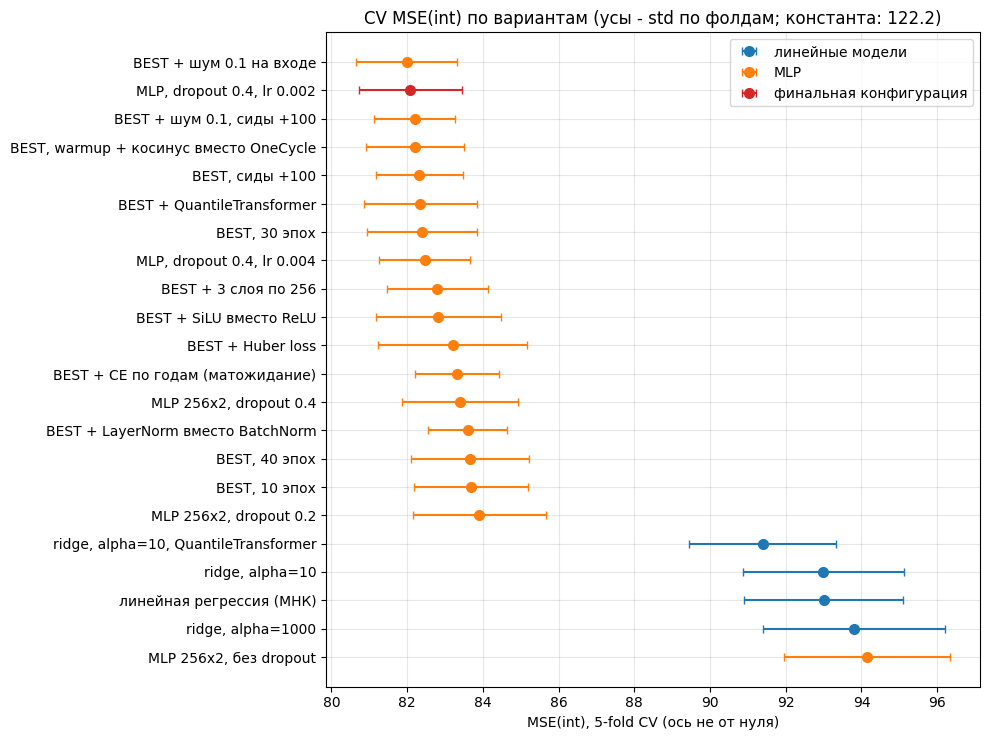

In [20]:
table = summary_table()
display(table.round(3))
print(f"вклад округления: от {table['вклад округления'].min():.3f} до {table['вклад округления'].max():.3f}, "
      f"в среднем {table['вклад округления'].mean():.3f} (1/12 = {1 / 12:.3f})")

t = table.drop(index="константа (среднее)").sort_values("MSE(int)", ascending=False)
kind = np.where(t.index == BEST_NAME, "финальная конфигурация",
                np.where(t.index.str.contains("MLP|BEST"), "MLP", "линейные модели"))
kind_colors = {"линейные модели": "C0", "MLP": "C1", "финальная конфигурация": "C3"}
# точки вместо столбцов: ось начинается не с нуля, столбцы визуально преувеличили бы разницу
fig, ax = plt.subplots(figsize=(10, 7.5))
pos = np.arange(len(t))
for k, c in kind_colors.items():
    m = kind == k
    ax.errorbar(t["MSE(int)"][m], pos[m], xerr=t["MSE(int) std"][m], fmt="o", color=c, ms=7, capsize=3, label=k)
ax.set_yticks(pos, t.index)
ax.set(title="CV MSE(int) по вариантам (усы - std по фолдам; константа: %.1f)" % table.loc["константа (среднее)", "MSE(int)"],
       xlabel="MSE(int), 5-fold CV (ось не от нуля)")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Что получилось:
- лучший вариант - `BEST` (MLP 256x2, BatchNorm, ReLU, dropout 0.4, lr 2e-3, OneCycle, 20 эпох): MSE 81.98 ± 1.37, после постобработки MSE(int) 82.09 (RMSE 9.05, MAE 6.33). Для сравнения: MSE(int) лучшей линейной модели - 91.39, константы - 122.19. Эта оценка немного оптимистична: lr и остальное выбирались по этим же фолдам и сидам, а с другими сидами тот же `BEST` дает 82.27 (MSE(int) 82.33);
- больше всего дали dropout (95.8 -> 83.3) и увеличение lr (83.3 -> 82.0), число эпох подобрано по CV (20 лучше, чем 10, 30 и 40). Остальные идеи (QuantileTransformer, LayerNorm, SiLU, третий слой, другое расписание, Huber, CE, шум на входе) не дали улучшения больше, чем разброс между сидами;
- вклад округления у вариантов от -0.03 до 0.16, в среднем 0.080 - около 1/12, как и ожидалось (разброс дает тот самый шумный перекрестный член). Вклад обрезки заметен только у линейных моделей и у сети без dropout, у которых бывают предсказания за пределами [1922, 2011]; у финальной сети он -0.016.

## 5. Свой оптимизатор

Оптимизатор из задания 3 (task3_optimizers.ipynb): `MyAdamW` - моя реализация AdamW (Loshchilov & Hutter, 2017) как наследника `torch.optim.Optimizer`. Ниже две ячейки скопированы из задания 3 без изменений: базовый класс `MyOptimizerBase` (общий цикл по параметрам) и сам `MyAdamW` (остальные мои оптимизаторы из задания 3 здесь не нужны).

In [21]:
def _check_hparam(ok, name, value):
    if not ok:
        raise ValueError(f"Invalid {name} value: {value}")


class MyOptimizerBase(torch.optim.Optimizer):
    """Общий каркас для моих оптимизаторов.

    От torch.optim.Optimizer берется только хранение param_groups / state,
    zero_grad и state_dict / load_state_dict. Сам шаг считается в наследниках:
    _init_state(p, group) - начальное состояние параметра (создается лениво,
    при первом шаге, когда у параметра появился градиент),
    _update(p, grad, state, group) - in-place обновление параметра.
    """

    def _init_state(self, p, group):
        return {}

    def _update(self, p, grad, state, group):
        raise NotImplementedError

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None:
                    continue
                if p.grad.is_sparse:
                    raise RuntimeError(f"{type(self).__name__} не поддерживает разреженные градиенты")
                state = self.state[p]
                if len(state) == 0:
                    state.update(self._init_state(p, group))
                self._update(p, p.grad, state, group)
        return loss

In [22]:
class MyAdamW(MyOptimizerBase):
    r"""AdamW (Loshchilov & Hutter, 2017): Adam с отделенным (decoupled) weight decay.
    Аналог torch.optim.AdamW, можно подставлять вместо него.

    p <- p * (1 - lr * wd)                              # weight decay мимо адаптивной нормировки
    m_t = beta1 * m_{t-1} + (1 - beta1) * g_t
    v_t = beta2 * v_{t-1} + (1 - beta2) * g_t^2         (amsgrad: v_max = max(v_max, v_t))
    m_hat = m_t / (1 - beta1^t),  v_hat = v_t / (1 - beta2^t)
    p <- p - lr * m_hat / (sqrt(v_hat) + eps)
    """

    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2, amsgrad=False):
        _check_hparam(lr >= 0.0, "learning rate", lr)
        _check_hparam(eps >= 0.0, "epsilon", eps)
        _check_hparam(0.0 <= betas[0] < 1.0, "beta1", betas[0])
        _check_hparam(0.0 <= betas[1] < 1.0, "beta2", betas[1])
        _check_hparam(weight_decay >= 0.0, "weight_decay", weight_decay)
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, amsgrad=amsgrad)
        super().__init__(params, defaults)

    def _init_state(self, p, group):
        state = {"step": 0, "exp_avg": torch.zeros_like(p), "exp_avg_sq": torch.zeros_like(p)}
        if group["amsgrad"]:
            state["max_exp_avg_sq"] = torch.zeros_like(p)
        return state

    def _update(self, p, grad, state, group):
        lr, (beta1, beta2), eps, wd = group["lr"], group["betas"], group["eps"], group["weight_decay"]
        state["step"] += 1
        t = state["step"]

        # 1) decoupled weight decay: уменьшаем сами веса, градиент не трогаем
        if wd != 0:
            p.mul_(1 - lr * wd)

        # 2) скользящие средние градиента и его квадрата
        exp_avg, exp_avg_sq = state["exp_avg"], state["exp_avg_sq"]
        exp_avg.lerp_(grad, 1 - beta1)  # = beta1 * m + (1 - beta1) * g
        exp_avg_sq.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)
        if group["amsgrad"]:
            torch.maximum(state["max_exp_avg_sq"], exp_avg_sq, out=state["max_exp_avg_sq"])
            exp_avg_sq = state["max_exp_avg_sq"]

        # 3) поправки на смещение (m_0 = v_0 = 0) и сам шаг
        bias_correction1 = 1 - beta1 ** t
        bias_correction2 = 1 - beta2 ** t
        denom = (exp_avg_sq.sqrt() / bias_correction2 ** 0.5).add_(eps)
        p.addcdiv_(exp_avg, denom, value=-lr / bias_correction1)

`fit_mlp` уже умеет брать `MyAdamW` (`opt="my"`). Обучим финальную конфигурацию с ним на тех же фолдах и с теми же сидами и сравним с `torch.optim.AdamW`. OneCycleLR меняет у оптимизатора не только `lr`, но и `betas[0]` (циклический момент) - в `MyAdamW` гиперпараметры читаются из `param_groups` на каждом шаге, так что шедулер работает с ним так же.

BEST, MyAdamW                          MSE  81.977 ± 1.368 | MSE(int)  82.088 | RMSE 9.0538 | MAE 6.3261 | 3.9 с/фолд
MSE по фолдам, torch.optim.AdamW: [79.8233, 82.6635, 81.444, 83.9665, 81.989]
MSE по фолдам, MyAdamW:           [79.8233, 82.6635, 81.444, 83.9665, 81.989]
max |разность OOF-предсказаний| = 0 лет


фолд 0: max |разность весов| = 0, max |разность предсказаний| = 0, время 5.2 с vs 4.8 с


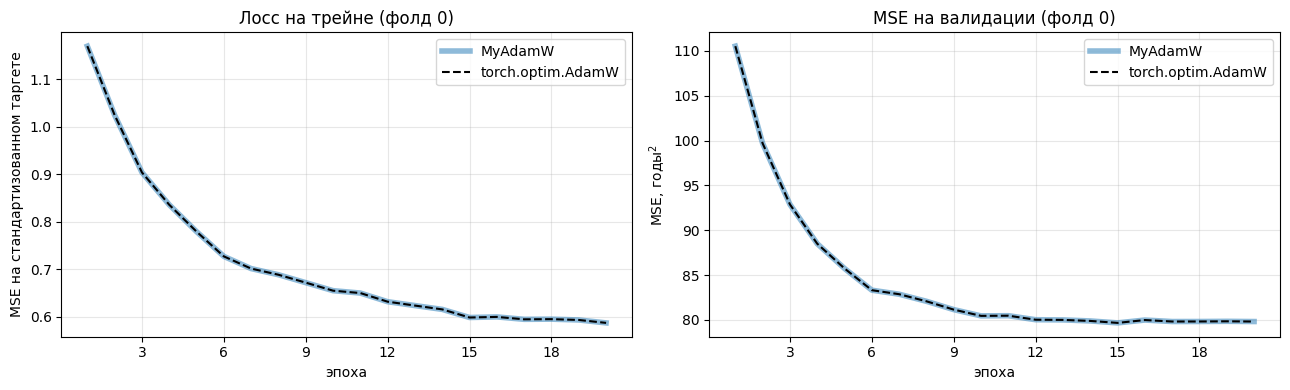

In [23]:
FINAL = {**BEST}
my = cross_validate(fit_mlp, "BEST, MyAdamW", **FINAL, opt="my")
ref = RESULTS[BEST_NAME]  # тот же конфиг с torch.optim.AdamW, посчитан выше
print("MSE по фолдам, torch.optim.AdamW:", ref["folds"].mse.round(4).tolist())
print("MSE по фолдам, MyAdamW:          ", my["folds"].mse.round(4).tolist())
print(f"max |разность OOF-предсказаний| = {np.abs(my['oof'] - ref['oof']).max():.3g} лет")

# фолд 0 еще раз, чтобы сравнить веса и кривые
tr, va = FOLDS[0]
runs = {}
for opt_name in ["adamw", "my"]:
    t0 = time.time()
    pred, curve, model = fit_mlp(X[tr], y[tr], X[va], seed=0, y_va=y[va], return_model=True, **FINAL, opt=opt_name)
    runs[opt_name] = dict(pred=pred, curve=curve, sd=model.state_dict(), sec=time.time() - t0)
w_diff = max((runs["adamw"]["sd"][k].float() - runs["my"]["sd"][k].float()).abs().max().item() for k in runs["my"]["sd"])
print(f"фолд 0: max |разность весов| = {w_diff:.3g}, max |разность предсказаний| = "
      f"{np.abs(runs['adamw']['pred'] - runs['my']['pred']).max():.3g}, время {runs['adamw']['sec']:.1f} с vs {runs['my']['sec']:.1f} с")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for key, label, style in [("my", "MyAdamW", dict(lw=4, alpha=0.5)), ("adamw", "torch.optim.AdamW", dict(ls="--", color="k"))]:
    ep = np.arange(1, len(runs[key]["curve"]["train_loss"]) + 1)
    axes[0].plot(ep, runs[key]["curve"]["train_loss"], label=label, **style)
    axes[1].plot(ep, runs[key]["curve"]["val_mse"], label=label, **style)
axes[0].set(title="Лосс на трейне (фолд 0)", xlabel="эпоха", ylabel="MSE на стандартизованном таргете")
axes[1].set(title="MSE на валидации (фолд 0)", xlabel="эпоха", ylabel="MSE, годы$^2$")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

Совпадение точное, а не приблизительное: MSE на всех фолдах одинаковые, разность OOF-предсказаний и весов после обучения ровно 0, кривые лежат друг на друге. Так и должно быть: `MyAdamW` делает те же операции в том же порядке, что и `torch.optim.AdamW` (decoupled decay `p *= 1 - lr * wd`, `lerp_` для первого момента, тот же знаменатель с поправками на смещение - это я сверял с исходниками torch еще в задании 3), а вся случайность (инициализация, перемешивание батчей, dropout) зафиксирована сидами. Время обучения тоже практически одинаковое (см. замер на фолде 0 в выводе выше, где обе модели учатся подряд; время на фолд в CV сравнивать не стоит, на общей машине оно от запуска к запуску скачет). Сеть маленькая, и питоновский цикл по 10 тензорам параметров незаметен на фоне forward / backward. Итого: с моим оптимизатором ничего не изменилось - ни качество, ни сами веса, поэтому финальную модель учу им.

## 6. Финальная модель и сабмишен

Обучаем одну модель с финальной конфигурацией на всех 14000 строках (скейлер и нормировка таргета пересчитываются на всем трейне), тем же расписанием на 20 эпох, оптимизатор - `MyAdamW`. Сид фиксирован. Предсказания теста обрезаются в [1922, 2011] и округляются до целых.

Расписание задано в эпохах, поэтому на полном трейне шагов оптимизатора примерно на четверть больше, чем на фолдах CV (28 батчей за эпоху вместо 22, всего 560 шагов вместо 440). Судя по п. 4.3, это безопасно: даже 30 эпох на CV (660 шагов) лишь немного хуже 20 (82.25 против 81.98), а данных на полном трейне тоже на четверть больше, т.е. каждый объект модель видит те же 20 раз.

In [24]:
SEED = 2026
test_raw, full_curve = fit_mlp(X, y, X_test, seed=SEED, **FINAL, opt="my")
test_pred = postprocess(test_raw)

# формат сабмишена: заголовок берем из sample_submission.csv, если он скачан, иначе id,year
sample_path = DATA / "sample_submission.csv"
id_col, target_col = pd.read_csv(sample_path, nrows=0).columns[:2] if sample_path.exists() else ("id", "year")
submission = pd.DataFrame({id_col: test_ids.values, target_col: test_pred})
assert len(submission) == len(X_test) == 6000 and submission[id_col].is_unique
submission.to_csv("submission.csv", index=False)
print("сохранено submission.csv:", submission.shape, "| dtype:", submission[target_col].dtype)
display(submission.head())
print(f"тест: среднее {test_pred.mean():.2f}, std {test_pred.std():.2f}, min {test_pred.min()}, max {test_pred.max()}")

сохранено submission.csv: (6000, 2) | dtype: int64


,id,year
0,3416,1999
1,18991,2004
2,11105,1997
3,18902,2001
4,18958,2003


тест: среднее 1998.07, std 6.79, min 1973, max 2010


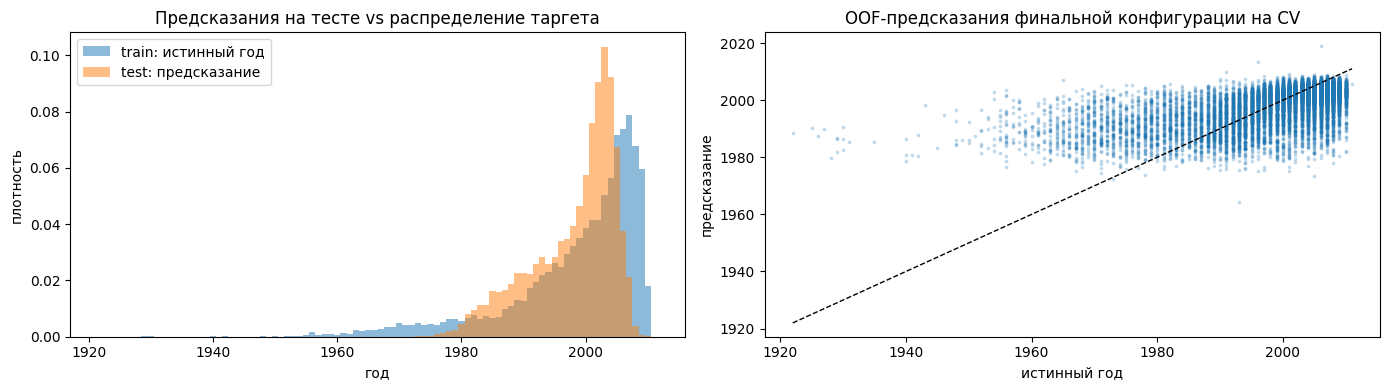

In [25]:
oof_best = RESULTS[BEST_NAME]["oof"]
bins = np.arange(YMIN, YMAX + 2) - 0.5
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(y, bins=bins, density=True, alpha=0.5, label="train: истинный год")
axes[0].hist(test_pred, bins=bins, density=True, alpha=0.5, label="test: предсказание")
axes[0].set(title="Предсказания на тесте vs распределение таргета", xlabel="год", ylabel="плотность")
axes[0].legend()
axes[1].scatter(y, oof_best, s=3, alpha=0.2)
axes[1].plot([YMIN, YMAX], [YMIN, YMAX], "k--", lw=1)
axes[1].set(title="OOF-предсказания финальной конфигурации на CV", xlabel="истинный год", ylabel="предсказание")
plt.tight_layout()
plt.show()

Предсказания на тесте лежат в диапазоне 1973-2010, среднее 1998.1 почти как у трейна (1998.4), но разброс заметно меньше (std 6.8 против 11.05). Модель, обученная на MSE, сжимает предсказания к среднему: на OOF-графике справа видно, что для старых песен (до 1980 года) предсказания систематически завышены. Для MSE это ожидаемо: старых песен мало, признаки слабо отличают их от новых, и осторожное предсказание ближе к среднему выгоднее.

## 7. Описание решения

Итоговое решение - одна полносвязная сеть на torch, без ансамблирования.

- Данные: 90 признаков из `train_x.csv`. Колонка-индекс (номер строки в исходном датасете) не используется, сторонних данных нет.
- Предобработка: StandardScaler, обученный на трейне. Таргет стандартизуется средним и std трейна, на выходе обратное преобразование.
- Модель: 90 -> [Linear(256) -> BatchNorm1d -> ReLU -> Dropout(0.4)] x 2 -> Linear(1), инициализация torch по умолчанию.
- Обучение: лосс MSE, оптимизатор `MyAdamW` (моя реализация AdamW из задания 3, с `torch.optim.AdamW` результат совпадает бит в бит), weight decay 1e-2, батч 512, 20 эпох (выбрано по CV), OneCycleLR с максимальным lr 2e-3 (30% шагов разгон, дальше косинус), шедулер шагает на каждом батче. Расписание фиксированное, без early stopping, сид 2026. Финальная модель учится на всех 14000 строках (те же 20 эпох, это 560 шагов вместо 440 на фолде CV).
- Постобработка: обрезка в [1922, 2011] и округление до целого года, как требуют правила.
- Качество на 5-fold CV: MSE 81.98 ± 1.37, MSE(int) 82.09, RMSE 9.05, MAE 6.33. Это число немного оптимистично, т.к. на тех же фолдах и сидах подбирались lr и остальные настройки; с другими сидами та же конфигурация дает MSE 82.27, MSE(int) 82.33, так что честная оценка MSE(int) - примерно 82.1-82.3. Константа дает MSE(int) 122.19, лучшая линейная модель (ridge + QuantileTransformer) - 91.39.
- Что помогло: dropout (без него сеть переобучается за 5 эпох; 95.8 -> 83.3), больший lr в OneCycle (83.3 -> 82.0) и длина расписания, подобранная по CV: 20 эпох (81.98) лучше, чем 10 (83.64), 30 (82.25) и 40 (83.54).
- Что не помогло: QuantileTransformer для сети, LayerNorm вместо BatchNorm, SiLU вместо ReLU, третий слой, warmup + косинус вместо OneCycle, Huber loss, классификация по годам с матожиданием, гауссов шум на входе.
- Правила соревнования: каждое предсказание (и на CV, и на тесте) - выход одной обученной модели, без усреднения по фолдам, сидам или чекпоинтам. Модель целиком на torch, sklearn используется только для KFold и скейлеров, pandas / numpy - для чтения данных и сборки сабмишена.

## Источники

- Описание датасета YearPredictionMSD (UCI): https://archive.ics.uci.edu/ml/datasets/YearPredictionMSD
- Million Song Dataset: http://labrosa.ee.columbia.edu/millionsong, статья: T. Bertin-Mahieux, D. Ellis, B. Whitman, P. Lamere. The Million Song Dataset. ISMIR 2011.
- Тембр: https://en.wikipedia.org/wiki/Timbre
- I. Loshchilov, F. Hutter. Decoupled Weight Decay Regularization, 2017. https://arxiv.org/abs/1711.05101
- L. N. Smith. A disciplined approach to neural network hyper-parameters: Part 1, 2018. https://arxiv.org/abs/1803.09820 и L. N. Smith, N. Topin. Super-Convergence, 2017. https://arxiv.org/abs/1708.07120 (расписание OneCycle)
- N. Srivastava et al. Dropout: A Simple Way to Prevent Neural Networks from Overfitting. JMLR, 2014.
- S. Ioffe, C. Szegedy. Batch Normalization, 2015. https://arxiv.org/abs/1502.03167
- J. L. Ba, J. R. Kiros, G. E. Hinton. Layer Normalization, 2016. https://arxiv.org/abs/1607.06450
- Y. Gorishniy et al. Revisiting Deep Learning Models for Tabular Data, 2021. https://arxiv.org/abs/2106.11959 (MLP с dropout как сильный бейзлайн для табличных данных)
- C. M. Bishop. Training with Noise is Equivalent to Tikhonov Regularization. Neural Computation, 1995.
- Документация PyTorch: [AdamW](https://pytorch.org/docs/stable/generated/torch.optim.AdamW.html), [OneCycleLR](https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.OneCycleLR.html), [BatchNorm1d](https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm1d.html)
- Документация scikit-learn: [KFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html), [QuantileTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.QuantileTransformer.html)